# COMP6008 Group 17 – Home Energy Scheduling: Environment Formulation

An RL agent controls a home's **battery**, **EV charging** and **two shiftable appliances** (washing machine, dishwasher), with power from **rooftop solar** and the **grid** under a time-of-use tariff. The goal is to minimise the daily electricity cost while charging the EV by its 07:00 departure and running both appliances before their deadlines. Weather (sunny / cloudy / rainy) changes solar output from day to day.

**Episode:** one day, 24 hourly steps, from 07:00 to 07:00 the next morning. Starting at 07:00 places the EV deadline exactly at the end of the episode.

## 1. Formulation questions

**Does the environment emit observations?** Yes. Each step it emits a continuous 15-dimensional vector:

| Index | Feature | Type | Range |
|---|---|---|---|
| 0, 1 | Hour of day as sin / cos (so 23:00 and 00:00 are close) | continuous | [−1, 1] |
| 2 | Home battery state of charge | continuous | [0, 1] |
| 3 | EV state of charge | continuous | [0, 1] |
| 4 | EV plugged in | binary | {0, 1} |
| 5, 6 | Solar output now / next hour (kW) | continuous | [0, 7.5] |
| 7 | Household base load (kW) | continuous | [0, 5] |
| 8, 9 | Grid price now / next hour ($/kWh) | continuous | [0.10, 0.55] |
| 10–12 | Weather one-hot (sunny, cloudy, rainy) | binary | {0, 1} |
| 13, 14 | Washing machine / dishwasher still pending | binary | {0, 1} |

The observation is richer than a single sensor reading $z_t$: it combines the current measurements with a one-hour look-ahead of solar and price (like a forecast a real home energy system would receive), i.e. $o_t = \{z_t, \hat z_{t+1}\}$.

**Does the environment emit rewards?** Yes, a scalar every hour, so the signal is dense:

$$r_t = -\big(\text{import}_t \cdot \text{price}_t - \text{export}_t \cdot \text{feed-in}\big) - \text{penalties}_t$$

Penalties: \$2 if an appliance passes its latest start time without running; \$1 per kWh the EV is below 80 % at 07:00 (given at the final step). The episode return is therefore minus the total daily cost including penalties.

**Does the environment accept actions that affect its evolution?** Yes. Discrete, 12 actions, `action = battery*4 + ev*2 + appliance`:

| Component | Values |
|---|---|
| battery | 0 = charge, 1 = idle, 2 = discharge |
| ev | 0 = wait, 1 = charge (only works while plugged in) |
| appliance | 0 = defer, 1 = start next pending appliance (only if past its earliest start) |

Actions change future states: battery and EV charge carry over between hours, and starting an appliance commits its load for the following hours. Infeasible choices simply have no effect, which keeps the action space fixed.

**Time per step:** a few arithmetic operations, measured below at roughly tens of microseconds per step, so a million steps (about 42,000 simulated days) takes well under a minute of environment time.

**Implementable in reasonable time?** Yes: synthetic profiles (`profiles.py`), no external data or special algorithms.

**Transition model $p(s_{t+1}, r_{t+1} \mid s_t, a_t)$:** deterministic given the day's profiles (battery/EV updates, appliance progress, energy balance). Stochasticity comes from the weather drawn at `reset()` (sunny 0.6 / cloudy 0.3 / rainy 0.1) and ±10 % noise on hourly solar and load.

## 2. Data profiles
Running this cell writes `profiles.py` so the environment and agent notebooks can import it.

In [1]:
%%writefile profiles.py
"""
profiles.py - Synthetic hourly data for the home energy scheduling environment.

Everything here is a 24-value array (one value per hour, index 0 = midnight).
All numbers are illustrative assumptions for a typical Perth household;
state them as assumptions in the report.

Usage:
    from profiles import sample_day
    day = sample_day(rng)          # rng = np.random.default_rng(seed)
    day["solar"], day["load"], day["price"], ...
"""

import numpy as np

HOURS = np.arange(24)

# ---------------------------------------------------------------------------
# Solar generation (kW) - bell curve between sunrise and sunset, scaled by weather
# ---------------------------------------------------------------------------
SOLAR_PEAK_KW = 5.0            # roughly a 6.6 kW rooftop system on a clear day
SUNRISE, SUNSET = 6, 18

WEATHER_TYPES = ["sunny", "cloudy", "rainy"]
WEATHER_PROBS = [0.6, 0.3, 0.1]                          # Perth is mostly sunny
WEATHER_SCALE = {"sunny": 1.0, "cloudy": 0.5, "rainy": 0.2}


def solar_profile(weather, rng=None, noise=0.1):
    """Hourly solar output (kW) for a given weather type."""
    curve = np.zeros(24)
    daylight = (HOURS >= SUNRISE) & (HOURS <= SUNSET)
    # half-sine shape: 0 at sunrise/sunset, peak at midday
    curve[daylight] = np.sin(np.pi * (HOURS[daylight] - SUNRISE) / (SUNSET - SUNRISE))
    solar = SOLAR_PEAK_KW * WEATHER_SCALE[weather] * curve
    if rng is not None:                                   # small random variation
        solar *= 1 + rng.normal(0, noise, 24)
    return np.clip(solar, 0, None)


# ---------------------------------------------------------------------------
# Household base load (kW) - things we do NOT control (fridge, lights, cooking)
# ---------------------------------------------------------------------------
BASE_LOAD = np.array([
    0.4, 0.3, 0.3, 0.3, 0.3, 0.4,    # 00-05 night
    0.8, 1.2, 1.0, 0.6, 0.5, 0.5,    # 06-11 morning peak
    0.6, 0.5, 0.5, 0.6, 0.9, 1.5,    # 12-17 afternoon
    2.0, 1.8, 1.4, 1.0, 0.7, 0.5,    # 18-23 evening peak
])


def load_profile(rng=None, noise=0.1):
    load = BASE_LOAD.copy()
    if rng is not None:
        load *= 1 + rng.normal(0, noise, 24)
    return np.clip(load, 0.1, None)


# ---------------------------------------------------------------------------
# Time-of-use tariff ($/kWh) - cheap midday, expensive evening peak
# ---------------------------------------------------------------------------
PRICE_OFFPEAK, PRICE_MIDDAY, PRICE_PEAK = 0.25, 0.10, 0.55
FEED_IN_PRICE = 0.03            # paid for exporting solar to the grid


def price_profile():
    price = np.full(24, PRICE_OFFPEAK)
    price[9:15] = PRICE_MIDDAY       # 9am-3pm
    price[15:21] = PRICE_PEAK        # 3pm-9pm
    return price


# ---------------------------------------------------------------------------
# Home battery and EV
# ---------------------------------------------------------------------------
BATTERY = {"capacity_kwh": 10.0, "max_rate_kw": 5.0, "efficiency": 0.95}

EV = {
    "capacity_kwh": 60.0,
    "max_rate_kw": 7.0,
    "arrive_hour": 18,          # plugged in from 6pm ...
    "depart_hour": 7,           # ... until 7am next morning
    "arrive_soc": 0.4,          # 40% charge when it gets home
    "target_soc": 0.8,          # needs 80% by departure (penalty if not)
}


def ev_plugged_in():
    """Boolean array: True for hours the EV is at home and can charge."""
    return (HOURS >= EV["arrive_hour"]) | (HOURS < EV["depart_hour"])


# ---------------------------------------------------------------------------
# Shiftable appliances - must run once per day, agent chooses when
# ---------------------------------------------------------------------------
APPLIANCES = {
    "washing_machine": {"power_kw": 1.0, "duration_h": 2, "earliest": 7,  "deadline": 22},
    "dishwasher":      {"power_kw": 1.2, "duration_h": 2, "earliest": 8,  "deadline": 23},
}


# ---------------------------------------------------------------------------
# One episode = one simulated day
# ---------------------------------------------------------------------------
def sample_day(rng, weather=None):
    """Return all profiles for one day. Weather is random unless given."""
    if weather is None:
        weather = rng.choice(WEATHER_TYPES, p=WEATHER_PROBS)
    return {
        "weather": weather,
        "solar": solar_profile(weather, rng),
        "load": load_profile(rng),
        "price": price_profile(),
        "feed_in": FEED_IN_PRICE,
        "ev_plugged_in": ev_plugged_in(),
    }

Writing profiles.py


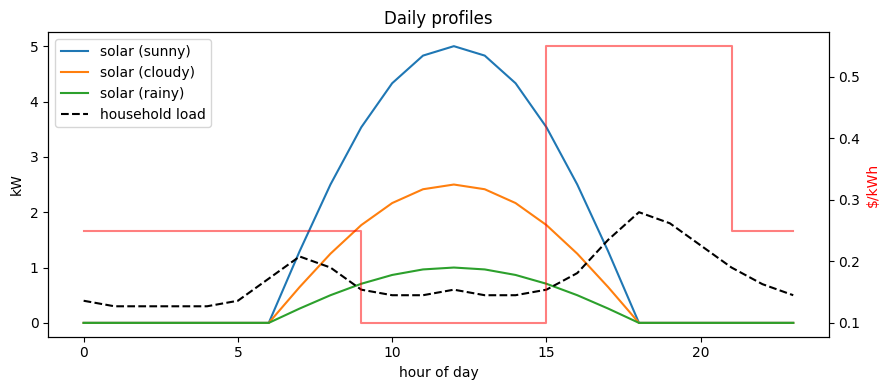

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import profiles as P

fig, ax1 = plt.subplots(figsize=(9, 4))
for w in P.WEATHER_TYPES:
    ax1.plot(P.HOURS, P.solar_profile(w), label=f"solar ({w})")
ax1.plot(P.HOURS, P.BASE_LOAD, "k--", label="household load")
ax1.set_xlabel("hour of day"); ax1.set_ylabel("kW")
ax2 = ax1.twinx()
ax2.step(P.HOURS, P.price_profile(), "r", where="post", alpha=0.5)
ax2.set_ylabel("$/kWh", color="r")
ax1.legend(loc="upper left"); ax1.set_title("Daily profiles")
plt.tight_layout(); plt.show()

## 3. Environment

Each `step()` follows this order, which defines the transition model:

1. Decode the action into battery / EV / appliance parts.
2. Start an appliance if requested and allowed; add the load of running appliances.
3. EV arrives home at 18:00 at 40 %; charge it if requested and plugged in.
4. Charge / discharge the home battery (95 % efficiency each way).
5. Energy balance → grid import (cost) or export (feed-in income).
6. Penalty for any appliance past its latest start time.
7. Advance the clock; at the final step, penalise any EV shortfall below 80 %.

In [3]:
%%writefile energy_env.py
"""
energy_env.py - Home energy scheduling environment (Gymnasium).

One episode = one day, 24 hourly steps, from 07:00 to 07:00 the next morning.
Starting at 07:00 means the EV's deadline (charged by 07:00 departure) falls
exactly at the end of the episode.

Observation (15 values, fixed order - do not change without telling the group):
    0 hour_sin, 1 hour_cos, 2 battery_soc, 3 ev_soc, 4 ev_plugged_in,
    5 solar_now, 6 solar_next, 7 load_now, 8 price_now, 9 price_next,
    10 sunny, 11 cloudy, 12 rainy, 13 washer_pending, 14 dishwasher_pending

Action (Discrete 12):  action = battery * 4 + ev * 2 + appliance
    battery:   0 = charge, 1 = idle, 2 = discharge
    ev:        0 = wait,   1 = charge
    appliance: 0 = defer,  1 = start next pending appliance
"""

import numpy as np
import gymnasium as gym
from gymnasium import spaces

import profiles as P

START_HOUR = 7
EV_PENALTY_PER_KWH = 1.0      # $ per kWh the EV is short at departure
APPLIANCE_PENALTY = 2.0       # $ if an appliance misses its deadline


def decode_action(action):
    """Split the single action number into its three parts."""
    action = int(action)
    return action // 4, (action // 2) % 2, action % 2


class EnergyEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, weather=None):
        super().__init__()
        self.fixed_weather = weather          # None = random weather each episode
        self.appliance_names = list(P.APPLIANCES)

        low = np.array([-1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=np.float32)
        high = np.array([1, 1, 1, 1, 1,
                         P.SOLAR_PEAK_KW * 1.5, P.SOLAR_PEAK_KW * 1.5, 5.0,
                         P.PRICE_PEAK, P.PRICE_PEAK,
                         1, 1, 1, 1, 1], dtype=np.float32)
        self.observation_space = spaces.Box(low, high, dtype=np.float32)
        self.action_space = spaces.Discrete(12)

    # ------------------------------------------------------------------ reset
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                    # sets self.np_random
        self.day = P.sample_day(self.np_random, self.fixed_weather)
        self.t = 0                                   # step counter 0..23
        self.battery_soc = 0.5
        self.ev_soc = P.EV["arrive_soc"]
        # per appliance: "pending" (not started), "running", "done", "missed"
        self.app_status = {n: "pending" for n in self.appliance_names}
        self.app_hours_left = {n: 0 for n in self.appliance_names}
        return self._obs(), {}

    # ------------------------------------------------------------------- step
    def step(self, action):
        assert self.action_space.contains(action)
        h = self.hour
        b_act, ev_act, app_act = decode_action(int(action))
        solar = self.day["solar"][h]
        load = self.day["load"][h]
        price = self.day["price"][h]
        penalty = 0.0

        # 1. Appliances: start the next pending one if allowed, then run them
        if app_act == 1:
            for n in self.appliance_names:
                spec = P.APPLIANCES[n]
                if self.app_status[n] == "pending" and h >= spec["earliest"]:
                    self.app_status[n] = "running"
                    self.app_hours_left[n] = spec["duration_h"]
                    break
        appliance_kwh = 0.0
        for n in self.appliance_names:
            if self.app_status[n] == "running":
                appliance_kwh += P.APPLIANCES[n]["power_kw"]
                self.app_hours_left[n] -= 1
                if self.app_hours_left[n] == 0:
                    self.app_status[n] = "done"

        # 2. EV arrives home at 18:00 with a fixed charge level
        if h == P.EV["arrive_hour"]:
            self.ev_soc = P.EV["arrive_soc"]
        ev_kwh = 0.0
        if ev_act == 1 and self.day["ev_plugged_in"][h]:
            ev_kwh = min(P.EV["max_rate_kw"], (1 - self.ev_soc) * P.EV["capacity_kwh"])
            self.ev_soc += ev_kwh / P.EV["capacity_kwh"]

        # 3. Home battery (efficiency loss on the way in and out)
        cap, rate, eff = (P.BATTERY[k] for k in ("capacity_kwh", "max_rate_kw", "efficiency"))
        batt_in = batt_out = 0.0
        if b_act == 0:                                   # charge
            batt_in = min(rate, (1 - self.battery_soc) * cap / eff)
            self.battery_soc += batt_in * eff / cap
        elif b_act == 2:                                 # discharge
            drawn = min(rate, self.battery_soc * cap)
            self.battery_soc -= drawn / cap
            batt_out = drawn * eff
        self.battery_soc = float(np.clip(self.battery_soc, 0, 1))

        # 4. Energy balance: positive = buy from grid, negative = sell
        net = load + appliance_kwh + ev_kwh + batt_in - solar - batt_out
        grid_import, grid_export = max(net, 0.0), max(-net, 0.0)
        cost = grid_import * price - grid_export * self.day["feed_in"]

        # 5. Penalties: appliance past its latest start time
        for n in self.appliance_names:
            spec = P.APPLIANCES[n]
            latest_start = spec["deadline"] - spec["duration_h"]
            if self.app_status[n] == "pending" and h >= latest_start:
                self.app_status[n] = "missed"
                penalty += APPLIANCE_PENALTY

        # 6. Advance time; at 07:00 the EV leaves - penalise any shortfall
        self.t += 1
        terminated = self.t == 24
        if terminated:
            shortfall = max(P.EV["target_soc"] - self.ev_soc, 0) * P.EV["capacity_kwh"]
            penalty += EV_PENALTY_PER_KWH * shortfall

        reward = -(cost + penalty)
        info = {"cost": cost, "penalty": penalty, "grid_import": grid_import,
                "grid_export": grid_export, "hour": h}
        return self._obs(), reward, terminated, False, info

    # --------------------------------------------------------------- helpers
    @property
    def hour(self):
        return (START_HOUR + self.t) % 24

    def _obs(self):
        h = self.hour
        nxt = (h + 1) % 24
        weather_onehot = [float(self.day["weather"] == w) for w in P.WEATHER_TYPES]
        pending = [float(self.app_status[n] == "pending") for n in self.appliance_names]
        obs = [
            np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
            self.battery_soc, self.ev_soc, float(self.day["ev_plugged_in"][h]),
            self.day["solar"][h], self.day["solar"][nxt], self.day["load"][h],
            self.day["price"][h], self.day["price"][nxt],
            *weather_onehot, *pending,
        ]
        return np.clip(np.array(obs, dtype=np.float32),
                       self.observation_space.low, self.observation_space.high)

Writing energy_env.py


## 4. Checks
Gymnasium's built-in checker, then one random episode printed hour by hour.

In [4]:
import importlib, energy_env
importlib.reload(energy_env)
from energy_env import EnergyEnv, decode_action
from gymnasium.utils.env_checker import check_env

env = EnergyEnv()
check_env(env)
print("Observation space:", env.observation_space.shape, " Action space:", env.action_space)

Observation space: (15,)  Action space: Discrete(12)


/usr/local/lib/python3.12/dist-packages/gymnasium/utils/env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


In [5]:
env = EnergyEnv(weather="sunny")
obs, _ = env.reset(seed=0)
print(" hour | action (b,ev,app) | batt  ev   | reward")
done = False
while not done:
    a = env.action_space.sample()
    obs, r, done, _, info = env.step(a)
    print(f"  {info['hour']:02d}  | {a:2d} {decode_action(a)}        | {obs[2]:.2f} {obs[3]:.2f} | {r:6.2f}")

 hour | action (b,ev,app) | batt  ev   | reward
  07  | 10 (2, 1, 0)        | 0.00 0.40 |   0.15
  08  |  4 (1, 0, 0)        | 0.00 0.40 |   0.04
  09  |  6 (1, 1, 0)        | 0.00 0.40 |   0.07
  10  |  6 (1, 1, 0)        | 0.00 0.40 |   0.11
  11  |  5 (1, 0, 1)        | 0.00 0.40 |   0.10
  12  |  6 (1, 1, 0)        | 0.00 0.40 |   0.07
  13  | 10 (2, 1, 0)        | 0.00 0.40 |   0.13
  14  | 10 (2, 1, 0)        | 0.00 0.40 |   0.10
  15  |  6 (1, 1, 0)        | 0.00 0.40 |   0.08
  16  |  5 (1, 0, 1)        | 0.00 0.40 |   0.01
  17  |  0 (0, 0, 0)        | 0.47 0.40 |  -3.67
  18  |  6 (1, 1, 0)        | 0.47 0.52 |  -5.10
  19  |  2 (0, 1, 0)        | 0.95 0.63 |  -7.67
  20  |  2 (0, 1, 0)        | 1.00 0.75 |  -4.93
  21  |  3 (0, 1, 1)        | 1.00 0.87 |  -1.99
  22  |  8 (2, 0, 0)        | 0.50 0.87 |   0.12
  23  |  0 (0, 0, 0)        | 0.98 0.87 |  -1.40
  00  |  9 (2, 0, 1)        | 0.47 0.87 |   0.13
  01  |  6 (1, 1, 0)        | 0.47 0.98 |  -1.83
  02  |  0 (0, 0, 0) 

## 5. Baselines

Two reference policies for the RL agents to beat:

- **Random:** uniform over the 12 actions.
- **Rule-based:** charge the battery when solar exceeds load, discharge during the evening peak, otherwise idle; charge the EV whenever plugged in outside the peak; start appliances during the cheap midday period.

In [6]:
def run_policy(policy, n_episodes=300, weather=None):
    env = EnergyEnv(weather)
    returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=ep)
        total, done = 0.0, False
        while not done:
            obs, r, done, _, _ = env.step(policy(obs))
            total += r
        returns.append(total)
    return np.mean(returns), np.std(returns)

rng = np.random.default_rng(0)
def random_policy(obs):
    return int(rng.integers(12))

def rule_policy(obs):
    solar, load, price, plugged = obs[5], obs[7], obs[8], obs[4]
    battery = 0 if solar > load else (2 if price >= P.PRICE_PEAK else 1)
    ev = 1 if plugged and price < P.PRICE_PEAK else 0
    appliance = 1 if price <= P.PRICE_MIDDAY else 0
    return battery * 4 + ev * 2 + appliance

print(f"{'policy':<8}{'weather':<9}{'mean return':>12}{'std':>8}")
for name, pol in [("random", random_policy), ("rule", rule_policy)]:
    for w in [None] + P.WEATHER_TYPES:
        m, s = run_policy(pol, weather=w)
        print(f"{name:<8}{(w or 'mixed'):<9}{m:>12.2f}{s:>8.2f}")

policy  weather   mean return     std


random  mixed          -21.03    2.97

random  sunny          -19.96    2.88


random  cloudy         -21.48    3.19
random  rainy          -22.67    3.02


rule    mixed          -12.60    0.81
rule    sunny          -12.06    0.37


rule    cloudy         -12.94    0.28
rule    rainy          -14.17    0.29


## 6. Time per step

In [7]:
env = EnergyEnv()
env.reset(seed=0)
def one_step():
    _, _, done, _, _ = env.step(env.action_space.sample())
    if done:
        env.reset()
%timeit one_step()

26.7 μs ± 3.17 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## 7. Using the environment in the agent notebooks

```python
from energy_env import EnergyEnv
env = EnergyEnv()            # random weather each episode
obs, info = env.reset(seed=0)
obs, reward, terminated, truncated, info = env.step(action)   # action in 0..11
```

`EnergyEnv(weather="rainy")` fixes the weather, which is useful for the per-weather comparison.